# 10 · Ward effects: funnel plot and narrative regimes
**Funnel plot.** Observed vs expected dried sources per ward, with expectations from a landscape-only model; wards
outside the 99.8 % limits and the overdispersion factor φ (≈ 1 if wards differ only by chance given landscape).

**Narrative regimes.** Wards with ≥ 8 dried sources are clustered by the shares of reported causes and periods
(Hellinger geometry, Ward linkage, K by silhouette); Mantel and partial Mantel tests ask whether narrative similarity
follows geography or landscape (`src/unsupervised.py`).

In [1]:
import sys, os, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)
M, F = ROOT / "results/metrics", ROOT / "results/figures"
def table(name, **kw):
    t = pd.read_csv(M / name, **kw)
    return t.round(4)
def fig(name, width=1100):
    display(Image(filename=str(F / name), width=width))

,n_wards,overdispersion_phi,chi2_p,n_outside_95,expected_outside_95,n_outside_998,expected_outside_998,n_high_998,n_low_998
0,75,5.4878,0.0,26,3.75,13,0.15,6,7


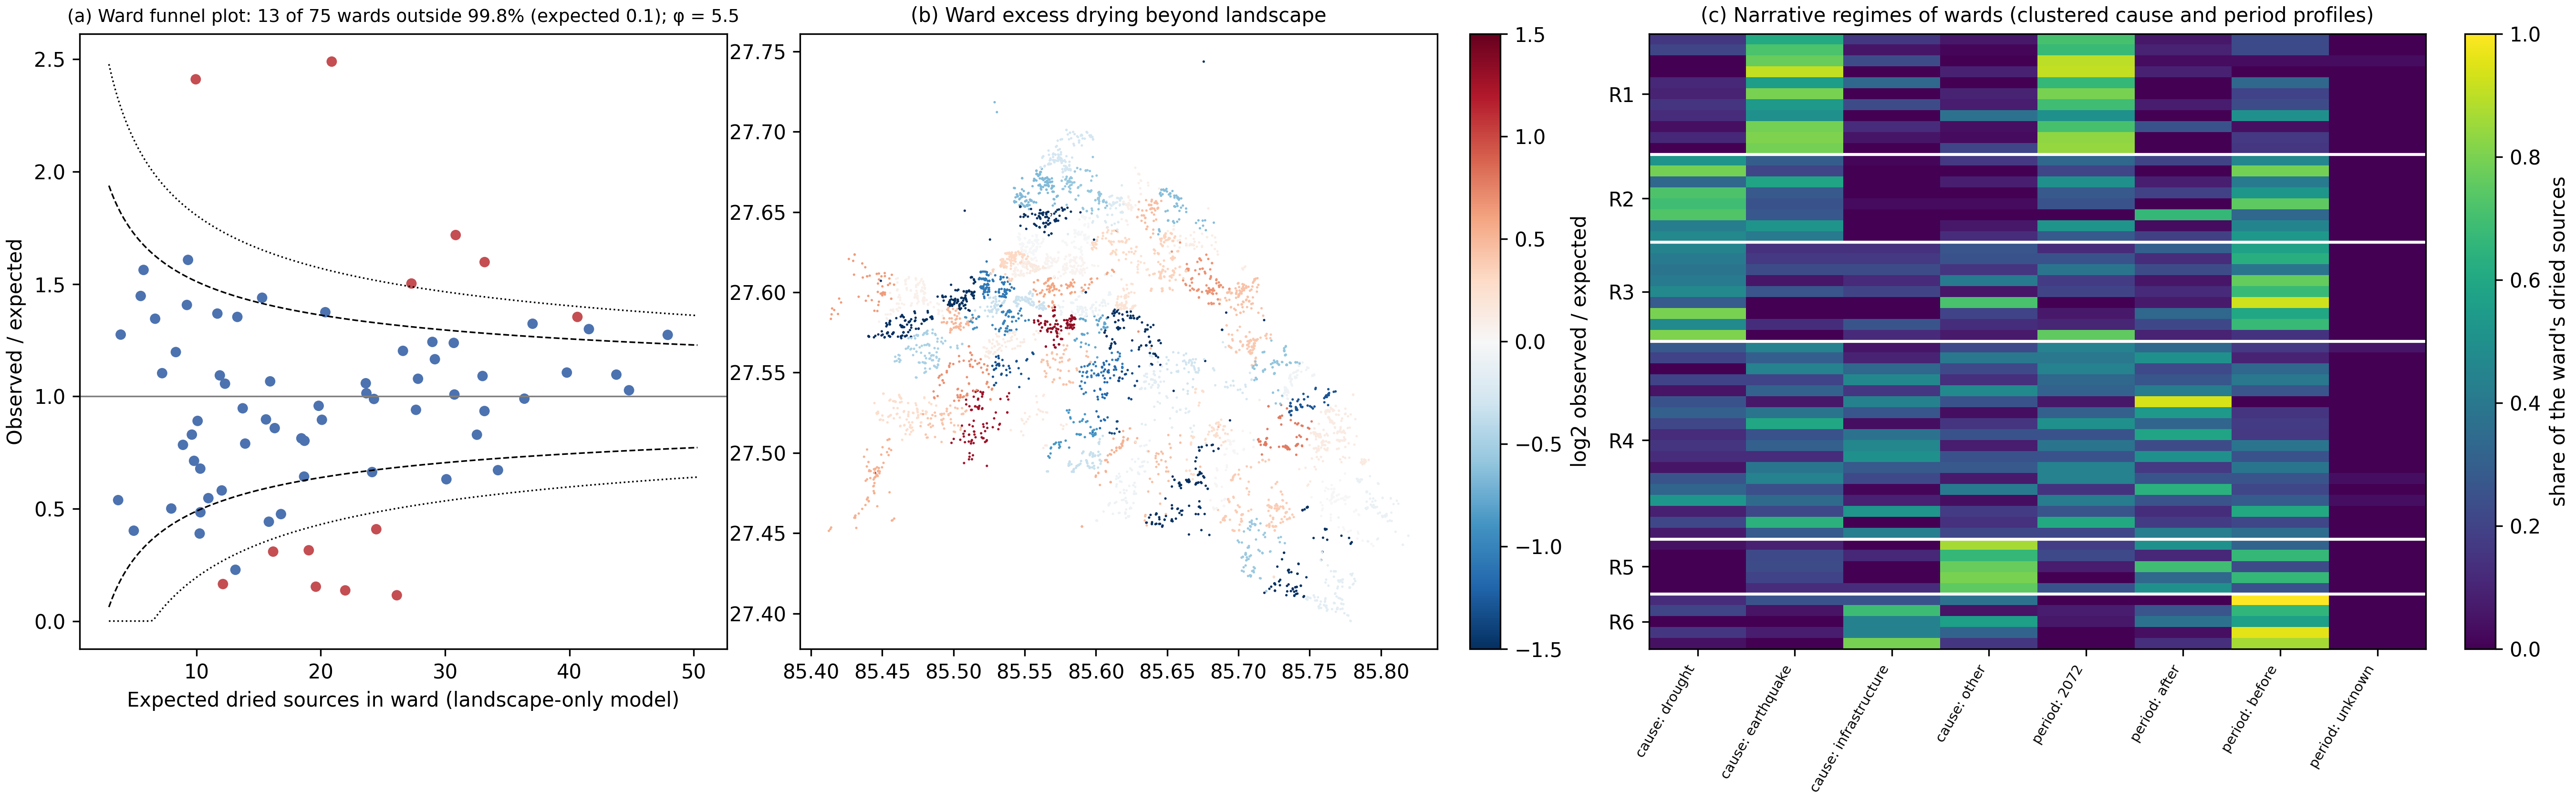

In [2]:
display(table("un_ward_funnel_summary.csv")); fig("un_wards.png")

In [3]:
table("un_ward_funnel.csv").sort_values("z")

,ward,n,observed,expected,var,municipality,sdr,z,outside_95,outside_998
10,Dhulikhel_2,86,3,26.1200,17.3883,Dhulikhel,0.1149,-5.5444,True,True
62,Roshi RM_6,106,3,21.9747,15.7464,Roshi RM,0.1365,-4.7817,True,True
21,Namobuudha_2,61,3,19.6096,12.9179,Namobuudha,0.1530,-4.6213,True,True
22,Namobuudha_3,46,6,19.0411,10.1011,Namobuudha,0.3151,-4.1033,True,True
69,Temal_4,58,10,24.4693,12.9083,Temal,0.4087,-4.0273,True,True
...,...,...,...,...,...,...,...,...,...,...
17,Dhulikhel_9,97,41,27.2952,18.4738,Dhulikhel,1.5021,3.1886,True,True
43,Panchkhal_11,93,53,33.1784,19.5337,Panchkhal,1.5974,4.4848,True,True
4,Bethanchownk_5,81,24,9.9548,8.3035,Bethanchownk,2.4109,4.8741,True,True
70,Temal_5,77,53,30.8523,17.5830,Temal,1.7179,5.2818,True,True


## Narrative regimes

In [4]:
display(table("un_narrative_k_selection.csv")); display(pd.read_csv(M / "un_narrative_regimes.csv", index_col=0).round(3)); table("un_narrative_mantel.csv")

,k,silhouette,selected
0,2,0.2068,False
1,3,0.1910,False
2,4,0.1886,False
3,5,0.2159,False
4,6,0.2206,True


,cause: drought,cause: earthquake,cause: infrastructure_development,cause: other,period: 2072,period: after,period: before,period: unknown,n_dried,n_wards
regime,,,,,,,,,,
R1,0.092,0.708,0.109,0.091,0.749,0.055,0.192,0.003,22.182,11
R2,0.585,0.351,0.006,0.058,0.296,0.171,0.533,0.000,37.750,8
R3,0.500,0.110,0.139,0.251,0.230,0.173,0.597,0.000,28.111,9
R4,0.191,0.333,0.264,0.211,0.346,0.384,0.262,0.007,24.222,18
R5,0.009,0.174,0.047,0.770,0.146,0.427,0.426,0.000,13.400,5
R6,0.108,0.077,0.521,0.294,0.028,0.163,0.809,0.000,26.200,5


,test,mantel_r,p
0,narrative ~ geography,-0.0439,0.786
1,narrative ~ landscape,0.0422,0.254
2,narrative ~ geography | landscape,-0.0850,0.915
3,narrative ~ landscape | geography,0.0841,0.132


In [5]:
pd.read_csv(M / "un_ward_narratives.csv", index_col=0).round(2).sort_values("regime")

,cause: drought,cause: earthquake,cause: infrastructure_development,cause: other,period: 2072,period: after,period: before,period: unknown,regime,n_dried,municipality
ward_id,,,,,,,,,,,
Temal_9,0.16,0.61,0.16,0.06,0.71,0.06,0.23,0.00,R1,31,Temal
Panchkhal_11,0.21,0.72,0.06,0.02,0.68,0.09,0.23,0.00,R1,53,Panchkhal
Panchkhal_9,0.00,0.77,0.23,0.00,0.90,0.03,0.03,0.03,R1,30,Panchkhal
Roshi RM_2,0.00,0.91,0.00,0.09,0.91,0.09,0.00,0.00,R1,11,Roshi RM
Panauti_1,0.11,0.56,0.33,0.00,0.67,0.00,0.33,0.00,R1,9,Panauti
Temal_4,0.10,0.80,0.00,0.10,0.80,0.00,0.20,0.00,R1,10,Temal
Panauti_10,0.15,0.54,0.23,0.08,0.69,0.08,0.23,0.00,R1,13,Panauti
Bethanchownk_6,0.12,0.50,0.00,0.38,0.50,0.00,0.50,0.00,R1,8,Bethanchownk
Bethanchownk_5,0.04,0.79,0.12,0.04,0.71,0.25,0.04,0.00,R1,24,Bethanchownk
